# Machine Learning Pipeline

Now that we have experience preparing data for input to machine learning libraries, the next step will be to train, tune, and test a model.  You will perform all three of these steps in this hands-on activity.

The assignment consists of the following steps:

1. Load two datasets and prepare their representations and labels for model input. 
2. Split the data into training and testing.
3. Select a model, and identify the parameters to tune.
4. Tune the model.
5. Evaluate the model's performance.

In [9]:
import logging
logging.getLogger("scapy.runtime").setLevel(logging.ERROR)

from netml.pparser.parser import PCAP
from netml.utils.tool import dump_data, load_data

import pandas as pd

## Convert the Packet Capture Into Flows

1. Load the two packet captures for HTTP requests and Log4j scan, 
2. convert them into traffic flows, 
3. generate features from the flow,  
4. label the traffic,
5. align the two feature sets to the same number of columns and concatenate them into one 2D matrix, with the labels in a separate vector (as in Hands-On 7).

Do not scale the features yet. Any feature scaling (min-max, z-score) is fit on the training set only, after the split below.

In [10]:
data_dir = "/home/frank/ml-systems/docs/notebooks/data"

# 1. Load the two packet captures: http (regular traffic) and log4j (scan)
http_pcap = PCAP(f"{data_dir}/http.pcap", flow_ptks_thres=2, random_state=42, verbose=0)
log4j_pcap = PCAP(f"{data_dir}/log4j.pcap", flow_ptks_thres=2, random_state=42, verbose=0)

# 2. Convert the packets into flows
http_pcap.pcap2flows()
log4j_pcap.pcap2flows()
print("Number of http flows: ", len(http_pcap.flows))
print("Number of log4j flows:", len(log4j_pcap.flows))

# 3. Generate features from each flow (inter-arrival times)
http_pcap.flow2features("IAT", fft=False, header=False)
log4j_pcap.flow2features("IAT", fft=False, header=False)
http_features = pd.DataFrame(http_pcap.features)
log4j_features = pd.DataFrame(log4j_pcap.features)
print("http feature shape: ", http_features.shape)
print("log4j feature shape:", log4j_features.shape)

# 5. Align the two feature sets: pad the narrower one with zeros, then concatenate
n_cols = max(http_features.shape[1], log4j_features.shape[1])
http_features = http_features.reindex(columns=range(n_cols), fill_value=0)
log4j_features = log4j_features.reindex(columns=range(n_cols), fill_value=0)
X = pd.concat([http_features, log4j_features], ignore_index=True)

# 4. Labels in a separate vector: 0 = http (regular), 1 = log4j (scan)
y = pd.Series([0] * len(http_features) + [1] * len(log4j_features), name="label")

print("X shape:", X.shape)
print(y.value_counts())

Number of http flows:  291
Number of log4j flows: 4795
http feature shape:  (291, 92)
log4j feature shape: (4795, 5)
X shape: (5086, 92)
label
1    4795
0     291
Name: count, dtype: int64


## Evaluating a Machine Learning Model

The goal of supervised learning is to train a model that takes examples and predicts labels for these examples that are as close as possible to the actual labels. For instance, in this example above, a model might take features from a traffic trace and predict whether the traffic constitutes regular web traffic or a scan.

How do you measure whether the model is succeeding if you don't know the true labels for new observations? The way to solve this problem is to test the performance of the trained algorithm on additional data that it has never seen, but for which you already know the correct labels. 

This requires that you train the algorithm using only a portion of the entire labeled dataset (the **training set**) and withold the rest of the labeled data (the **test set**) for testing how well the model generalizes to new information. 

To evaluate the model, we will need to split the data into train and test sets.

### Split into Training and Test Sets

Split your data into a training and test set using scikit-learn. A common split is to train on 80% of your data, while withholding 20% of the data.

If your model benefits from scaled features, fit the scaler on `X_train` only and apply the fitted scaler to `X_test`. Fitting it on the full matrix before splitting leaks test-set statistics into training (the golden rule from Lecture 7).


In [11]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

# 70% train / 30% test. stratify=y keeps the http/log4j ratio the same in both splits,
# so both classes appear in training and in testing.
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, stratify=y, random_state=42
)
print("train:", y_train.value_counts().to_dict(), " test:", y_test.value_counts().to_dict())

# Fit the scaler on the training set only, then apply it to both sets
scaler = StandardScaler().fit(X_train)
X_train_s = scaler.transform(X_train)
X_test_s = scaler.transform(X_test)

train: {1: 3356, 0: 204}  test: {1: 1439, 0: 87}


### Training Your Model

Now that you have split your data into training and testing sets, you are ready to train and evaluate a model. 

Import a machine learning model of your choice, use your training set to train the model, and use the test set to evaluate it. 

In [12]:
from sklearn.linear_model import LogisticRegression

clf = LogisticRegression(max_iter=1000)
clf.fit(X_train_s, y_train)

print("train accuracy:", round(clf.score(X_train_s, y_train), 4))
print("test accuracy: ", round(clf.score(X_test_s, y_test), 4))

train accuracy: 0.9736
test accuracy:  0.9692


### Test Your Trained Model

You can now evaluate how well your trained model works.  There are several valuable ways to visualize your results. You might use techniques such as a confusion matrix, or a receiver operating characteristic (ROC) curve. Below we will gain some experience plotting both of those.  This [documentation](https://scikit-learn.org/stable/auto_examples/miscellaneous/plot_display_object_visualization.html) may help you with plotting these results.

#### Confusion Matrix 

A confusion matrix is a one way to understand errors of different types. We can see a lot of examples off diagonal, suggesting a fair number of incorrect answers.

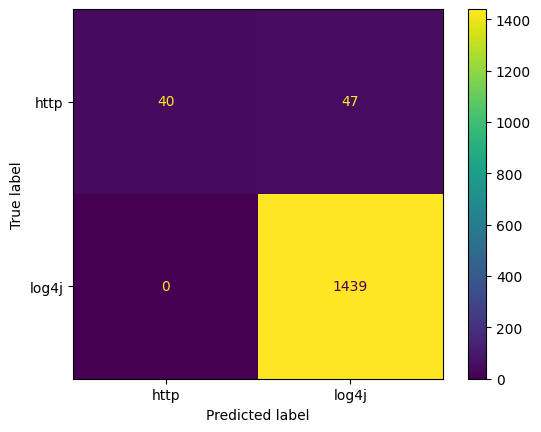

Precision: 0.968
Recall:    1.0


In [13]:
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay, precision_score, recall_score

y_pred = clf.predict(X_test_s)

ConfusionMatrixDisplay.from_predictions(y_test, y_pred, display_labels=["http", "log4j"])
plt.show()

# Positive class = log4j (label 1)
print("Precision:", round(precision_score(y_test, y_pred), 3))
print("Recall:   ", round(recall_score(y_test, y_pred), 3))

#### Receiver Operating Characteristic

Some models can output different classes based on a threshold that is set for the decision. 

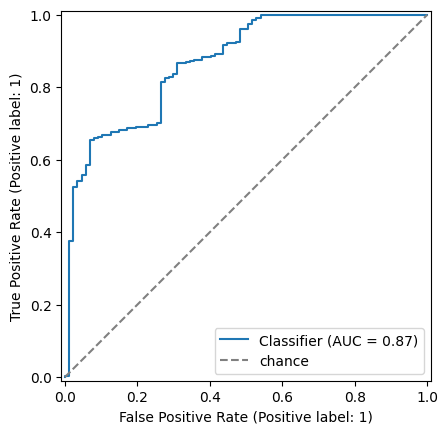

In [14]:
from sklearn.metrics import RocCurveDisplay

# Probability of the positive class (log4j) for each test flow
y_score = clf.predict_proba(X_test_s)[:, 1]

RocCurveDisplay.from_predictions(y_test, y_score)
plt.plot([0, 1], [0, 1], "--", color="gray", label="chance")
plt.legend()
plt.show()

#### Area Under the Curve (AUC)

From the ROC above, you can also compute a metric called the area under the curve (AUC). Visually, this is the area under the curve that you just plotted. You could see, intuitively, that the "best" performance should yield an AUC of 1, and the worst performance would yield an AUC closer to 0.5.

Scikit learn also has a function for computing AUC.  Compute the area under the curve.

In [15]:
from sklearn.metrics import roc_auc_score

auc = roc_auc_score(y_test, y_score)
print("AUC: {:.3f}".format(auc))

AUC: 0.870


#### Precision–Recall Curve and Average Precision

The ROC curve plots the true positive rate against the false positive rate as the decision threshold varies. A related plot is the **precision–recall (PR) curve**, which plots precision (of the examples the model flagged as positive, what fraction really are positive?) against recall (of the truly positive examples, what fraction did the model flag?) as the threshold varies.

The PR curve is often preferred when the positive class is rare, which is the common case in systems and security problems: attacks, spam, and failures are a tiny fraction of all traffic. With a rare positive class, the false positive *rate* stays small even when the model raises a large number of false alarms, because the denominator (all negatives) is huge. The ROC curve can therefore look excellent while an operator sees mostly false alarms. Precision, in contrast, is computed only over the examples the model flagged, so the PR curve exposes exactly that problem.

The single-number summary of the PR curve is **average precision (AP)**, which is analogous to AUC for the ROC curve. A random classifier has an AP equal to the fraction of positive examples, not 0.5.

Plot the PR curve for your model using `precision_recall_curve` and `PrecisionRecallDisplay`, and compute the average precision with `average_precision_score`. Compare the shape of the PR curve and the AP value to the ROC curve and AUC that you computed above.

Average precision: 0.987


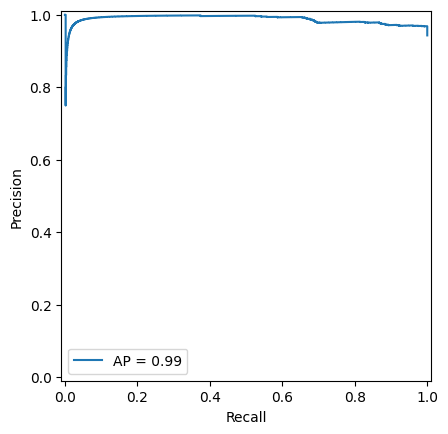

Fraction of positive (log4j) test examples: 0.943


In [16]:
from sklearn.metrics import precision_recall_curve, average_precision_score, PrecisionRecallDisplay

# Scores for the positive class (log4j) on the test set
y_score = clf.predict_proba(X_test_s)[:, 1]

# Precision, recall, and thresholds
precision, recall, thresholds = precision_recall_curve(y_test, y_score)

# Average precision
ap = average_precision_score(y_test, y_score)
print("Average precision: {:.3f}".format(ap))

# Plot the precision-recall curve
PrecisionRecallDisplay(precision=precision, recall=recall, average_precision=ap).plot()
plt.show()

# Fraction of positive test examples = AP of a random classifier
print("Fraction of positive (log4j) test examples: {:.3f}".format(y_test.mean()))

## Thought Question

Which evaluation model is more appropriate, and when (i.e., under what circumstances)? When might you care more about looking at the confusion matrix (or model accuracy) vs. the ROC, or the area under the curve?

When is the precision–recall curve more informative than the ROC curve? Think about what happens to each curve as the positive class becomes rarer, and about what an operator who has to investigate every alarm actually cares about.